# Section 1 — Import Libraries

In [34]:
# ============================================================
# Notebook 3 : Prediction, Explainability & Evaluation
# Section 1 : Import Libraries
# ============================================================

import os
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf

from tensorflow import keras

import cv2

from sklearn.metrics import (

    accuracy_score,

    precision_score,

    recall_score,

    f1_score,

    confusion_matrix,

    classification_report

)

warnings.filterwarnings("ignore")

print("Libraries Imported Successfully")

Libraries Imported Successfully


In [35]:
# ============================================================
# Project Paths
# ============================================================

import os

PROJECT_DIR = "D:/Brac thesis"

DATASET_DIR = os.path.join(
    PROJECT_DIR,
    "dataset"
)

PROCESSED_DATASET_DIR = os.path.join(
    DATASET_DIR,
    "processed"
)

METADATA_DIR = os.path.join(
    DATASET_DIR,
    "metadata"
)

MODELS_DIR = os.path.join(
    PROJECT_DIR,
    "models",
    "resnet50"
)

RESULTS_DIR = os.path.join(
    PROJECT_DIR,
    "results"
)

PREDICTIONS_DIR = os.path.join(
    RESULTS_DIR,
    "predictions"
)

EXPLAINABILITY_DIR = os.path.join(
    RESULTS_DIR,
    "explainability"
)

GRADCAM_DIR = os.path.join(
    EXPLAINABILITY_DIR,
    "gradcam"
)

HEATMAPS_DIR = os.path.join(
    EXPLAINABILITY_DIR,
    "heatmaps"
)

for directory in [
    PREDICTIONS_DIR,
    GRADCAM_DIR,
    HEATMAPS_DIR
]:
    os.makedirs(directory, exist_ok=True)

# ============================================================
# Dataset and Model Files
# ============================================================

TEST_CSV = os.path.join(
    PROCESSED_DATASET_DIR,
    "test.csv"
)

METADATA_PATH = os.path.join(
    METADATA_DIR,
    "metadata.json"
)

MODEL_PATH = os.path.join(
    MODELS_DIR,
    "skin_condition_identifier_resnet50.keras"
)

print("Paths Ready")

Paths Ready


In [36]:
# ============================================================
# Load Metadata
# ============================================================

with open(

    METADATA_PATH,

    "r"

) as file:

    metadata = json.load(

        file

    )

IMAGE_HEIGHT = metadata["image_height"]

IMAGE_WIDTH = metadata["image_width"]

CHANNELS = metadata["channels"]

NUM_CLASSES = metadata["total_labels"]

CLASS_NAMES = metadata["labels"]

LABEL_TO_INDEX = metadata["label_to_index"]

INDEX_TO_LABEL = metadata["index_to_label"]

print("Metadata Loaded Successfully")

Metadata Loaded Successfully


In [37]:
# ============================================================
# Load Trained Model
# ============================================================

model = keras.models.load_model(

    MODEL_PATH

)

print("Model Loaded Successfully")

Model Loaded Successfully


In [38]:
# ============================================================
# Model Information
# ============================================================

print("=" * 70)

print("MODEL INFORMATION")

print("=" * 70)

print(f"Model Name      : {model.name}")

print(f"Input Shape     : {model.input_shape}")

print(f"Output Shape    : {model.output_shape}")

print(f"Total Labels    : {NUM_CLASSES}")

MODEL INFORMATION
Model Name      : Skin_Disease_Classifier_resnet
Input Shape     : (None, 224, 224, 3)
Output Shape    : (None, 12)
Total Labels    : 12


# Section 2 — Load Test Image

In [39]:
# ============================================================
# Section 2 : Load Test Dataset
# ============================================================

test_df = pd.read_csv(

    TEST_CSV

)

print(

    f"Total Test Images : {len(test_df)}"

)

Total Test Images : 1242


In [40]:
# # ============================================================
# # Select Image
# # ============================================================

IMAGE_PATH = "D:/Brac thesis/dataset/processed/Images/Acne_Mild_acne_mild_001.jpg"
TRUE_LABEL = "Acne_Mild"
# IMAGE_PATH = None
# if IMAGE_PATH is None:

#     sample = test_df.sample(

#         n=1,

#         random_state=None

#     ).iloc[0]

#     IMAGE_PATH = sample["filepath"]

#     TRUE_LABEL = sample["label"]

# else:

#     TRUE_LABEL = "Unknown"

print(

    "Image Selected Successfully"

)

Image Selected Successfully


In [41]:
# ============================================================
# Load Image
# ============================================================

image = tf.io.read_file(

    IMAGE_PATH

)

image = tf.io.decode_image(

    image,

    channels=CHANNELS,

    expand_animations=False

)

image.set_shape(

    [

        IMAGE_HEIGHT,

        IMAGE_WIDTH,

        CHANNELS

    ]

)

image = tf.cast(

    image,

    tf.float32

)

input_tensor = tf.expand_dims(

    image,

    axis=0

)

print(

    "Image Loaded Successfully"

)

Image Loaded Successfully


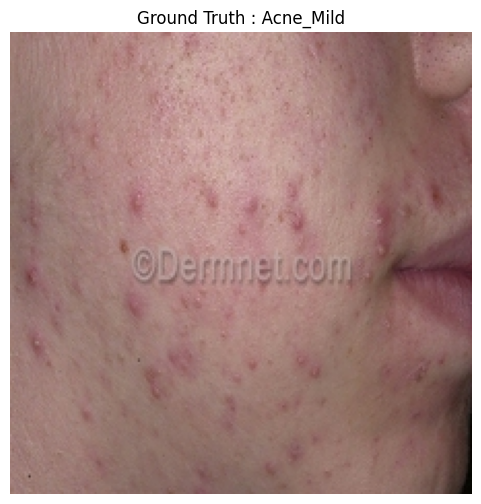

In [42]:
# ============================================================
# Display Image
# ============================================================

plt.figure(

    figsize=(6,6)

)

plt.imshow(

    tf.cast(

        image,

        tf.uint8

    )

)

plt.title(

    f"Ground Truth : {TRUE_LABEL}"

)

plt.axis(

    "off"

)

plt.show()

In [43]:
# ============================================================
# Image Information
# ============================================================

print("=" * 70)

print("IMAGE INFORMATION")

print("=" * 70)

print(f"Path        : {IMAGE_PATH}")

print(f"True Label  : {TRUE_LABEL}")

print(f"Shape       : {image.shape}")

IMAGE INFORMATION
Path        : D:/Brac thesis/dataset/processed/Images/Acne_Mild_acne_mild_001.jpg
True Label  : Acne_Mild
Shape       : (224, 224, 3)


# Section 3 — Predict All Label Probabilities

In [44]:
# ============================================================
# Section 3 : Predict
# ============================================================

predictions = model.predict(

    input_tensor,

    verbose=0

)

probabilities = predictions[0]

print("Prediction Completed Successfully")

Prediction Completed Successfully


In [45]:
# ============================================================
# Prediction Table
# ============================================================

prediction_df = pd.DataFrame(

    {

        "Label": CLASS_NAMES,

        "Probability": probabilities

    }

)

prediction_df["Probability (%)"] = (

    prediction_df["Probability"] * 100

)

prediction_df = prediction_df.sort_values(

    by="Probability",

    ascending=False

).reset_index(

    drop=True

)

print("Prediction Table Created Successfully")

Prediction Table Created Successfully


In [46]:
# ============================================================
# Prediction Result
# ============================================================

print("=" * 70)

print("PREDICTED PROBABILITIES")

print("=" * 70)

display(

    prediction_df
)

PREDICTED PROBABILITIES


,Label,Probability,Probability (%)
0,Acne_Mild,5.313084e-01,53.130840
1,Acne_Moderate,4.832236e-01,48.322365
2,Acne_Severe,1.722288e-02,1.722288
3,Eczema_Mild,2.672343e-03,0.267234
4,Eczema_Moderate,1.498957e-03,0.149896
5,Eczema_Severe,1.721124e-05,0.001721
6,burn_Mild,1.158902e-06,0.000116
7,Normal_dry,6.620025e-07,0.000066
8,burn_Severe,6.434076e-07,0.000064
9,burn_Moderate,5.865705e-07,0.000059


In [47]:
# ============================================================
# Organized Prediction Results
# ============================================================

prediction_dict = {}

# Build dictionary dynamically
for label, probability in zip(

    CLASS_NAMES,

    probabilities

):

    disease, severity = label.split("_", 1)

    if disease not in prediction_dict:

        prediction_dict[disease] = {}

    prediction_dict[disease][severity] = probability * 100

print("=" * 70)

print("PREDICTION RESULTS")

print("=" * 70)

for disease in sorted(prediction_dict.keys()):

    print()

    print(disease)

    print("-" * 40)

    severities = prediction_dict[disease]

    for severity in sorted(severities.keys()):

        print(

            f"{severity:<15}: "

            f"{severities[severity]:6.2f}%"

        )

PREDICTION RESULTS

Acne
----------------------------------------
Mild           :  53.13%
Moderate       :  48.32%
Severe         :   1.72%

Eczema
----------------------------------------
Mild           :   0.27%
Moderate       :   0.15%
Severe         :   0.00%

Normal
----------------------------------------
dry            :   0.00%
normal         :   0.00%
oily           :   0.00%

burn
----------------------------------------
Mild           :   0.00%
Moderate       :   0.00%
Severe         :   0.00%


In [48]:
# ============================================================
# Top Prediction
# ============================================================

predicted_label = prediction_df.loc[

    0,

    "Label"

]

predicted_probability = prediction_df.loc[

    0,

    "Probability (%)"

]

print("=" * 70)

print("TOP PREDICTION")

print("=" * 70)

print(f"Predicted Label : {predicted_label}")

print(f"Confidence      : {predicted_probability:.2f}%")

TOP PREDICTION
Predicted Label : Acne_Mild
Confidence      : 53.13%


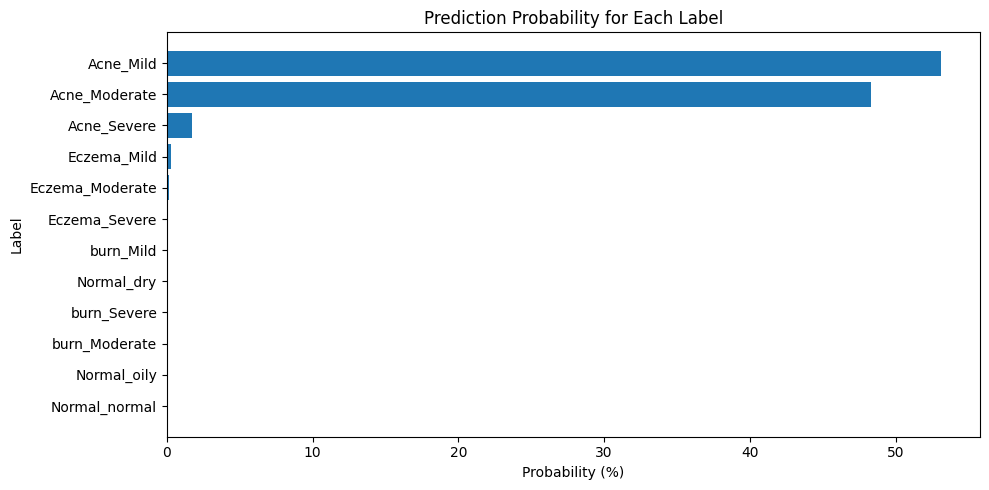

In [49]:
# ============================================================
# Probability Distribution
# ============================================================

plt.figure(

    figsize=(10,5)

)

plt.barh(

    prediction_df["Label"],

    prediction_df["Probability (%)"]

)

plt.xlabel(

    "Probability (%)"

)

plt.ylabel(

    "Label"

)

plt.title(

    "Prediction Probability for Each Label"

)

plt.gca().invert_yaxis()

plt.tight_layout()

plt.show()

# Section 4 — Build Grad-CAM

In [50]:
# ============================================================
# Section 4 : Last Convolution Layer
# ============================================================

base_model = model.get_layer(

    "resnet50"

)

last_conv_layer = None

for layer in reversed(

    base_model.layers

):

    if isinstance(

        layer,

        tf.keras.layers.Conv2D

    ):

        last_conv_layer = layer

        break

print("=" * 70)

print("LAST CONVOLUTION LAYER")

print("=" * 70)

print(last_conv_layer.name)

LAST CONVOLUTION LAYER
conv5_block3_3_conv


In [51]:
# ============================================================
# Build Grad-CAM Model
# ============================================================

gradcam_model = tf.keras.Model(

    inputs=base_model.input,

    outputs=[

        last_conv_layer.output,

        base_model.output

    ]

)

print("Grad-CAM Model Created Successfully")

Grad-CAM Model Created Successfully


In [52]:
# ============================================================
# Grad-CAM Function
# ============================================================

classifier_layers = model.layers[3:]


def generate_gradcam(

    image,

    class_index

):

    x = tf.keras.applications.resnet.preprocess_input(

        image

    )

    with tf.GradientTape() as tape:

        conv_outputs, features = gradcam_model(

            x,

            training=False

        )

        predictions = features

        for layer in classifier_layers:

            predictions = layer(

                predictions,

                training=False

            )

        class_score = predictions[

            :,

            class_index

        ]

    gradients = tape.gradient(

        class_score,

        conv_outputs

    )

    pooled_gradients = tf.reduce_mean(

        gradients,

        axis=(0, 1, 2)

    )

    conv_outputs = conv_outputs[0]

    heatmap = tf.reduce_sum(

        conv_outputs * pooled_gradients,

        axis=-1

    )

    heatmap = tf.maximum(

        heatmap,

        0

    )

    heatmap = heatmap / (

        tf.reduce_max(

            heatmap

        ) + 1e-8

    )

    return heatmap.numpy()

Heatmap Shape : (7, 7)


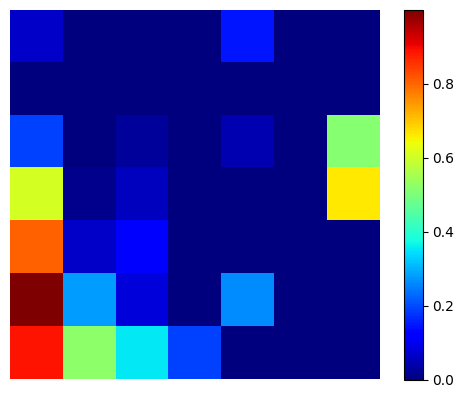

In [53]:
# ============================================================
# Test Grad-CAM
# ============================================================

heatmap = generate_gradcam(

    input_tensor,

    0

)

print(

    "Heatmap Shape :",

    heatmap.shape

)

plt.imshow(

    heatmap,

    cmap="jet"

)

plt.colorbar()

plt.axis("off")

plt.show()

# Section 5 — Visualize Grad-CAM for Every Label

In [54]:
# ============================================================
# Section 5 : Overlay Grad-CAM
# ============================================================

def overlay_gradcam(

    image,

    heatmap,

    alpha=0.4

):

    heatmap = cv2.resize(

        heatmap,

        (

            IMAGE_WIDTH,

            IMAGE_HEIGHT

        )

    )

    heatmap = np.uint8(

        255 * heatmap

    )

    heatmap = cv2.applyColorMap(

        heatmap,

        cv2.COLORMAP_JET

    )

    image = image.numpy().astype(

        np.uint8

    )

    overlay = cv2.addWeighted(

        image,

        1 - alpha,

        heatmap,

        alpha,

        0

    )

    overlay = cv2.cvtColor(

        overlay,

        cv2.COLOR_BGR2RGB

    )

    return overlay

print("Overlay Function Ready")

Overlay Function Ready


In [55]:
# ============================================================
# Generate Grad-CAM
# ============================================================

gradcam_results = []

for class_index in range(

    NUM_CLASSES

):

    heatmap = generate_gradcam(

        input_tensor,

        class_index

    )

    overlay = overlay_gradcam(

        image,

        heatmap

    )

    probability = probabilities[

        class_index

    ] * 100

    gradcam_results.append(

        {

            "label": CLASS_NAMES[class_index],

            "probability": probability,

            "overlay": overlay

        }

    )

print("Grad-CAM Generated Successfully")

Grad-CAM Generated Successfully


In [56]:
# ============================================================
# Sort Results
# ============================================================

gradcam_results = sorted(

    gradcam_results,

    key=lambda item: item["probability"],

    reverse=True

)

print("Results Sorted Successfully")

Results Sorted Successfully


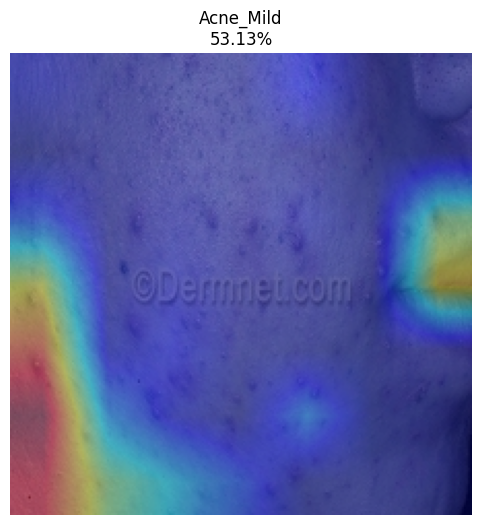

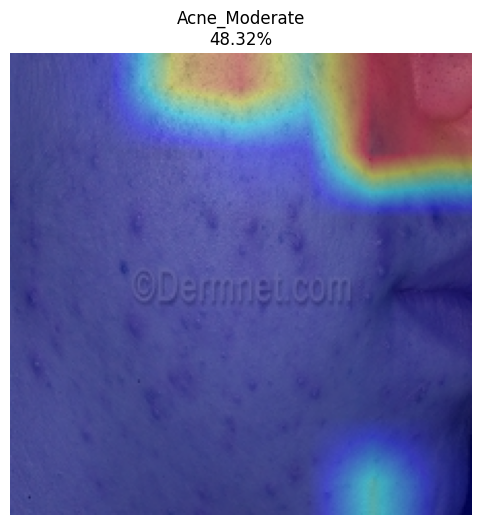

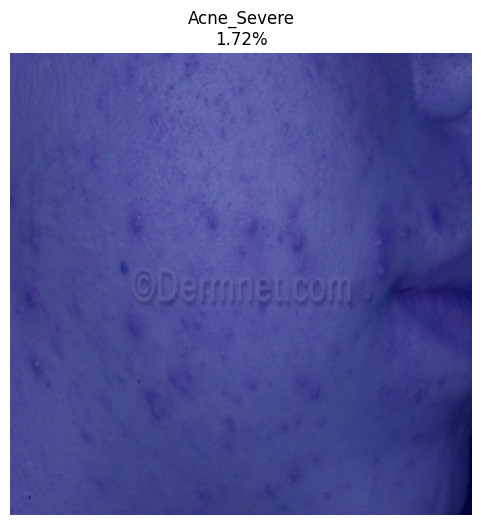

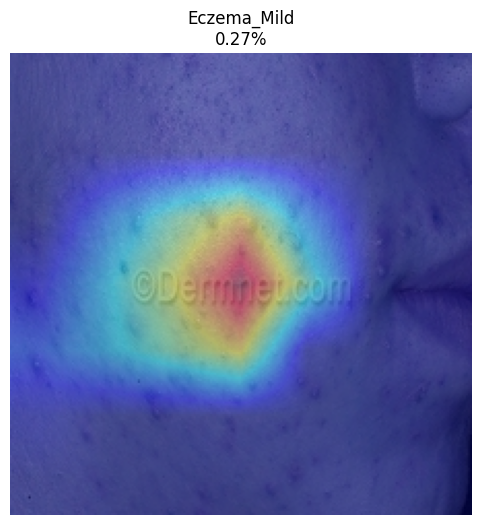

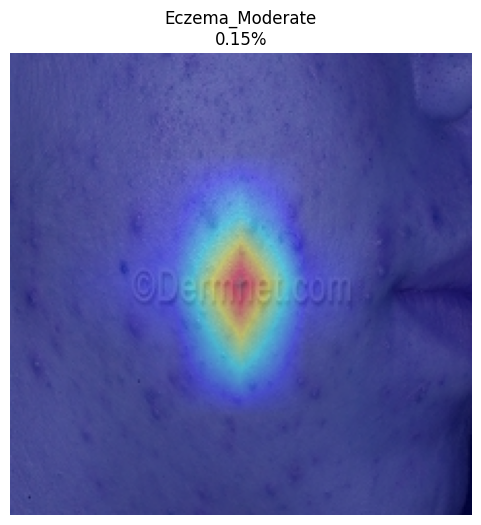

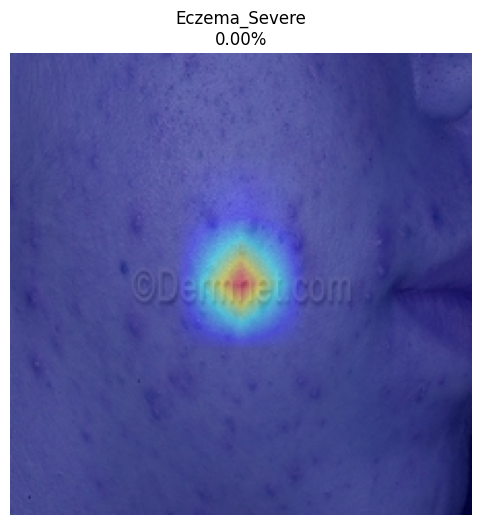

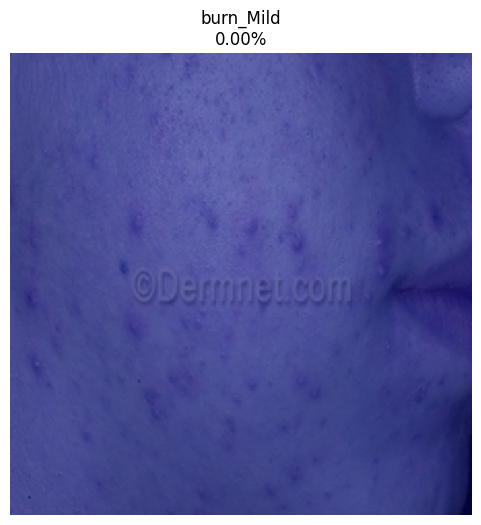

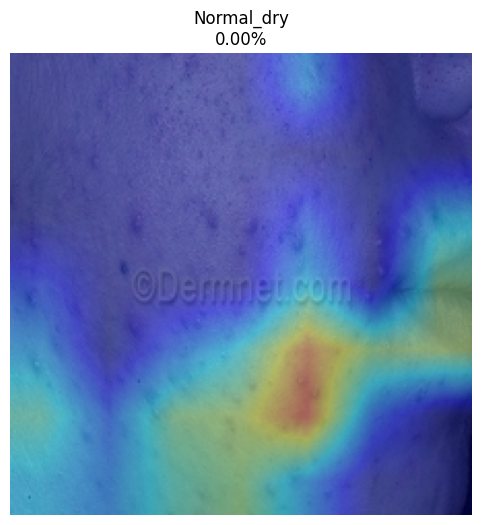

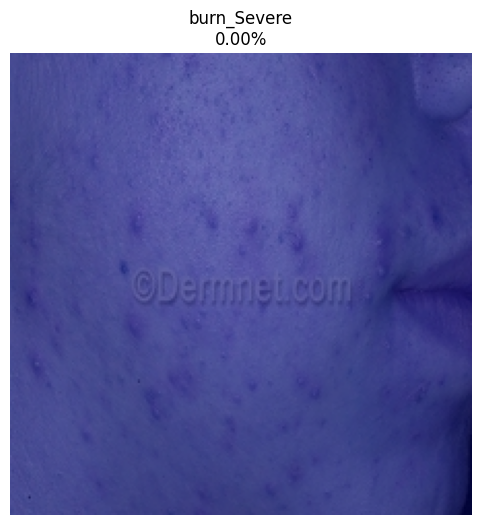

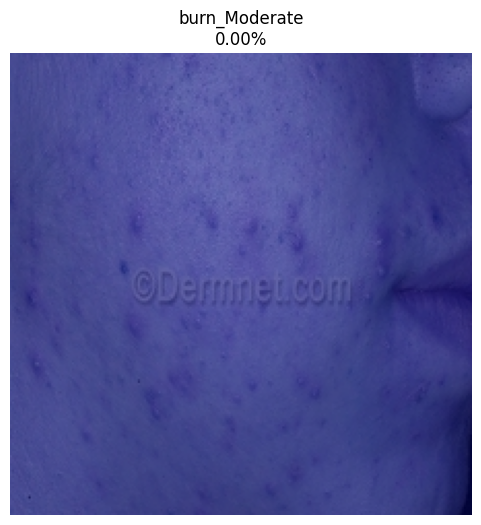

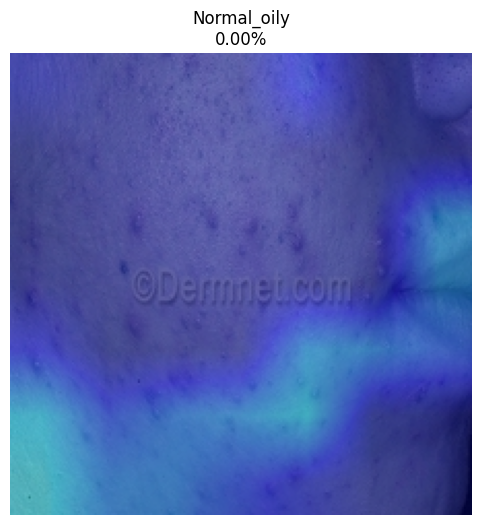

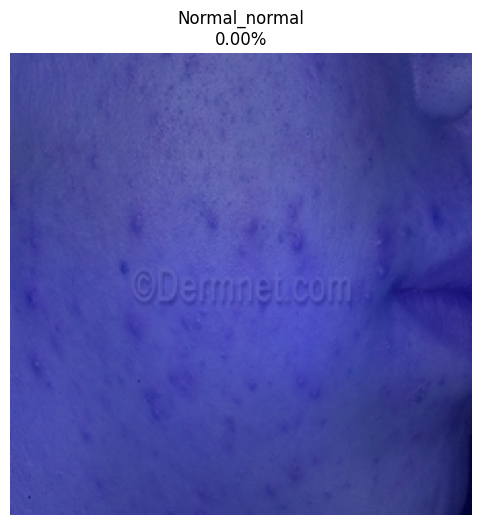

In [57]:
# ============================================================
# Display Grad-CAM
# ============================================================

for result in gradcam_results:

    plt.figure(

        figsize=(6,6)

    )

    plt.imshow(

        result["overlay"]

    )

    plt.title(

        f"{result['label']}\n"

        f"{result['probability']:.2f}%"

    )

    plt.axis(

        "off"

    )

    plt.show()

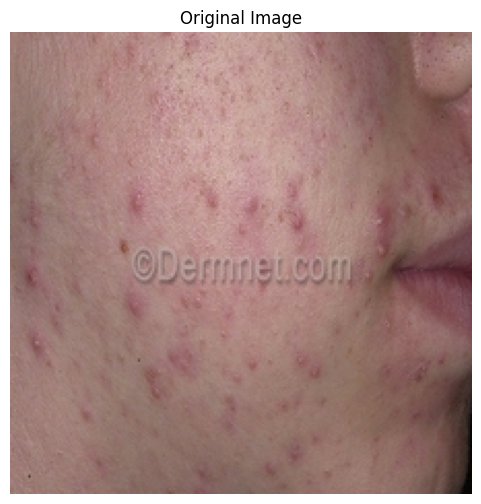

In [58]:
# ============================================================
# Original Image
# ============================================================

plt.figure(

    figsize=(6,6)

)

plt.imshow(

    tf.cast(

        image,

        tf.uint8

    )

)

plt.title(

    "Original Image"

)

plt.axis(

    "off"

)

plt.show()

# Section 6 — Evaluate Model

In [59]:
# ============================================================
# Section 6 : Load Test Dataset
# ============================================================

test_df = pd.read_csv(

    TEST_CSV

)

print(

    f"Total Test Images : {len(test_df)}"

)

Total Test Images : 1242


In [60]:
# ============================================================
# Image Loading Function
# ============================================================

def load_image(

    image_path,

    label

):

    image = tf.io.read_file(

        image_path

    )

    image = tf.io.decode_image(

        image,

        channels=CHANNELS,

        expand_animations=False

    )

    image.set_shape(

        [

            IMAGE_HEIGHT,

            IMAGE_WIDTH,

            CHANNELS

        ]

    )

    image = tf.cast(

        image,

        tf.float32

    )

    label = tf.one_hot(

        label,

        depth=NUM_CLASSES,

        dtype=tf.float32

    )

    return image, label

print("Image Loader Ready")

Image Loader Ready


In [61]:
# ============================================================
# Prepare Test Dataset
# ============================================================

test_image_paths = test_df["filepath"].values

test_labels = test_df["label"].map(

    LABEL_TO_INDEX

).values

test_dataset = tf.data.Dataset.from_tensor_slices(

    (

        test_image_paths,

        test_labels

    )

)

test_dataset = test_dataset.map(

    load_image,

    num_parallel_calls=tf.data.AUTOTUNE

)

test_dataset = test_dataset.batch(

    32

).prefetch(

    tf.data.AUTOTUNE

)

print("Test Dataset Ready")

Test Dataset Ready


In [62]:
# ============================================================
# Predict Test Dataset
# ============================================================

predictions = model.predict(

    test_dataset,

    verbose=1

)

predicted_labels = np.argmax(

    predictions,

    axis=1

)

true_labels = np.argmax(

    np.concatenate(

        [

            labels.numpy()

            for _, labels in test_dataset

        ],

        axis=0

    ),

    axis=1

)

print("Prediction Completed Successfully")

39/39 ━━━━━━━━━━━━━━━━━━━━ 112s 3s/step
Prediction Completed Successfully


In [63]:
# ============================================================
# Evaluation Metrics
# ============================================================

accuracy = accuracy_score(

    true_labels,

    predicted_labels

)

precision = precision_score(

    true_labels,

    predicted_labels,

    average="weighted"

)

recall = recall_score(

    true_labels,

    predicted_labels,

    average="weighted"

)

f1 = f1_score(

    true_labels,

    predicted_labels,

    average="weighted"

)

print("=" * 70)

print("MODEL PERFORMANCE")

print("=" * 70)

print(f"Accuracy  : {accuracy:.4f}")

print(f"Precision : {precision:.4f}")

print(f"Recall    : {recall:.4f}")

print(f"F1 Score  : {f1:.4f}")

MODEL PERFORMANCE
Accuracy  : 0.7432
Precision : 0.7462
Recall    : 0.7432
F1 Score  : 0.7403


In [64]:
# ============================================================
# Classification Report
# ============================================================

report = classification_report(

    true_labels,

    predicted_labels,

    target_names=CLASS_NAMES

)

print(report)

                 precision    recall  f1-score   support

      Acne_Mild       0.78      0.75      0.77        97
  Acne_Moderate       0.71      0.57      0.63        97
    Acne_Severe       0.78      0.89      0.83        98
    Eczema_Mild       0.65      0.84      0.73        98
Eczema_Moderate       0.61      0.60      0.61        98
  Eczema_Severe       0.80      0.65      0.72        98
     Normal_dry       0.81      0.62      0.70       114
  Normal_normal       0.81      0.80      0.81       191
    Normal_oily       0.79      0.92      0.85       168
      burn_Mild       0.71      0.69      0.70        80
  burn_Moderate       0.63      0.68      0.66        73
    burn_Severe       0.77      0.67      0.71        30

       accuracy                           0.74      1242
      macro avg       0.74      0.72      0.73      1242
   weighted avg       0.75      0.74      0.74      1242



In [65]:
# ============================================================
# Confusion Matrix
# ============================================================

cm = confusion_matrix(

    true_labels,

    predicted_labels

)

cm_df = pd.DataFrame(

    cm,

    index=CLASS_NAMES,

    columns=CLASS_NAMES

)

display(cm_df)

,Acne_Mild,Acne_Moderate,Acne_Severe,Eczema_Mild,Eczema_Moderate,Eczema_Severe,Normal_dry,Normal_normal,Normal_oily,burn_Mild,burn_Moderate,burn_Severe
Acne_Mild,73,15,1,5,0,2,1,0,0,0,0,0
Acne_Moderate,18,55,17,3,1,1,2,0,0,0,0,0
Acne_Severe,1,7,87,1,1,1,0,0,0,0,0,0
Eczema_Mild,1,0,0,82,13,0,0,0,0,1,1,0
Eczema_Moderate,0,0,0,27,59,9,0,0,0,3,0,0
Eczema_Severe,0,0,4,5,22,64,0,0,0,0,3,0
Normal_dry,0,0,1,0,0,0,71,25,16,1,0,0
Normal_normal,0,0,0,0,0,0,12,153,26,0,0,0
Normal_oily,0,0,0,0,0,0,2,11,154,1,0,0
burn_Mild,0,0,1,2,1,1,0,0,0,55,20,0


In [66]:
# ============================================================
# Final Summary
# ============================================================

print("=" * 70)

print("FINAL EVALUATION")

print("=" * 70)

print(f"Total Test Images : {len(test_df)}")

print(f"Total Classes     : {NUM_CLASSES}")

print()

print(f"Accuracy          : {accuracy:.4f}")

print(f"Precision         : {precision:.4f}")

print(f"Recall            : {recall:.4f}")

print(f"F1 Score          : {f1:.4f}")

print("=" * 70)

FINAL EVALUATION
Total Test Images : 1242
Total Classes     : 12

Accuracy          : 0.7432
Precision         : 0.7462
Recall            : 0.7432
F1 Score          : 0.7403
